# Notebook 1: Soft Thinking on GSM8K and its Superposition Gap

**Course project: Foundations of LLMs (AI60213)**

**Paper:** Zhen Zhang et al., *Soft Thinking: Unlocking the Reasoning Potential of LLMs in Continuous Concept Space*, NeurIPS 2025 · [arXiv:2505.15778](https://arxiv.org/abs/2505.15778) · [official code](https://github.com/eric-ai-lab/Soft-Thinking)

This notebook implements **the paper's method** and **measures its limitation**. Our proposed fix (a concept adapter) is in **Notebook 2**, which links this notebook's saved outputs.

**Contents**

0. Briefing
1. Background: Soft Thinking
2. Setup: model, data, configuration
3. The method: Soft Thinking on GSM8K
4. The limitation: out-of-distribution concept tokens and the superposition gap
5. Findings

---
# Part 0: Briefing

**Method.** Soft Thinking lets a reasoning model think "between tokens". At every thinking step it feeds back a **concept token**, the probability-weighted mixture of token embeddings, instead of one sampled token. It is training-free.

**Limitation (stated by the authors).** The model was only ever trained on discrete tokens, so concept tokens are **out of distribution**. The paper's Cold Stop rule limits instability but does not resolve it.

**What this notebook does.**

1. Re-implements Soft Thinking (batched) and runs it on 250 GSM8K test questions with `Qwen/Qwen3-1.7B` in thinking mode.
2. Turns the limitation into measurable quantities: the **norm mismatch** of concept tokens and the **superposition gap**, i.e. how far the model's response to a mixture is from the superposition of its responses to each candidate token.

| Item | Choice |
|---|---|
| Model | `Qwen/Qwen3-1.7B`, thinking mode, frozen |
| Data | GSM8K, the first 250 test questions |
| Settings | temperature 0.6, top-k 15, top-p 0.95, min-p 0.001, Cold Stop $\tau = 0.01$ for 128 steps, 2048 thinking + 512 answer tokens |
| Hardware / time | one Kaggle T4; **FULL ≈ 1.5 h** (decoding ≈ 80 min, diagnosis ≈ 5 min), **QUICK ≈ 10 min** |

**Outputs used by Notebook 2:** `soft_test.pkl` (every answer and concept token), `diag_paper.pkl` (gap metrics), `soft_test_time.json`.

---
# Part 1: Background: Soft Thinking

## 1.1 Problem: discrete reasoning throws information away

Reasoning models (QwQ, DeepSeek-R1, Qwen3 in thinking mode) solve problems by writing a long chain of thought between `<think>` and `</think>`. At every step the model computes a full probability distribution $p_t$ over the vocabulary, and then **collapses it to a single token**:

$$x_{t+1} \sim p_t \quad(\text{or } x_{t+1} = \arg\max p_t), \qquad \mathbf{e}_{t+1} = E[x_{t+1}]$$

where $E \in \mathbb{R}^{|V| \times d}$ is the input embedding matrix. Everything else in $p_t$ (the second-best idea, the alternative wording, the "maybe it's 8, maybe it's 12" uncertainty) is discarded before the next step.

The paper argues that this has two costs:

* **Lost information:** Each step is a fixed point in embedding space, so the model can explore only one reasoning path at a time.
* **Wasted tokens:** Because one path is explored at a time, the model often needs long, redundant chains to reach the answer.

The authors try to find something related to -> **Can an LLM think "between" tokens without any retraining?**

## 1.2 Core idea: concept tokens

Instead of sampling one token, Soft Thinking keeps the (filtered) distribution itself and calls it a **concept token**:

$$\mathbf{c}_t = \text{normalize}\big(\text{filter}(p_t)\big) \in \Delta^{|V|-1}$$

The filter is a top-k / top-p (and min-p) cut that keeps only the plausible tokens, then renormalises. The next input to the model is **not** the embedding of one token but the **probability-weighted mixture of token embeddings**:

$${\;\tilde{\mathbf{e}}_{t+1} \;=\; \sum_{k \in V} c_t[k]\,\mathbf{e}(k) \;=\; \mathbf{c}_t^{\top} E\;}$$

Key properties:

| Property | Why it matters |
|---|---|
| **Training free** | Only the decoding loop changes and not model weights |
| **Strict generalisation of CoT** | If $\mathbf{c}_t$ is one-hot, $\tilde{\mathbf{e}}_{t+1} = \mathbf{e}(x_{t+1})$, then ordinary greedy CoT |
| **Same model input space** | $\tilde{\mathbf{e}}$ is a convex combination of real embeddings, so it lies inside the convex hull the model knows |
| **Interpretable** | The argmax of each concept token can be decoded to text which means the thinking trace stays interpretable |
| **Only the thinking phase is soft** | Once thinking ends, the answer is generated with normal discrete tokens |

The intuition is that a concept token "encapsulates multiple meanings from related discrete tokens", implicitly carrying several candidate reasoning paths forward at once.

## 1.3 Architecture: discrete CoT vs Soft Thinking

```mermaid
flowchart LR
  subgraph CoT["Standard CoT (discrete)"]
    direction TB
    A1["hidden state h_t"] --> A2["next-token distribution p_t"]
    A2 --> A3["pick ONE token<br/>x = argmax or sample"]
    A3 --> A4["look up its embedding e(x)"]
    A4 -->|"feed back as next input"| A1
  end
  subgraph ST["Soft Thinking (continuous concept space)"]
    direction TB
    B1["hidden state h_t"] --> B2["next-token distribution p_t"]
    B2 --> B3["concept token c_t<br/>top-k / top-p filter, renormalise"]
    B3 --> B4["probability-weighted mix<br/>e~ = sum_k c_t[k] * e(k)"]
    B4 -->|"feed back as next input"| B1
  end
  CoT ~~~ ST
```

## 1.4 Cold Stop: knowing when to stop thinking

Feeding mixtures the model never saw during training puts it **out of distribution**. Over long chains this can make generation unstable. Soft Thinking adds a simple, training-free guard called **Cold Stop**, based on the entropy of each concept token:

$$H(\mathbf{c}_t) = -\sum_{k} c_t[k]\,\log c_t[k]$$

* Low entropy means the model is **confident** about what comes next.
* If $H(\mathbf{c}_t) < \tau$ for $k$ **consecutive** steps, the model has converged, so Soft Thinking inserts `</think>` and switches to answering.

This cuts off unnecessary thinking (fewer tokens) and limits how long the model drifts in the out-of-distribution regime. Thinking also ends normally when the argmax of the concept token is `</think>`, or when the token budget runs out.

### Full pipeline

```mermaid
flowchart TD
  Q["Question + instruction<br/>prompt ends with #lt;think#gt;"] --> P["Prefill: one forward pass,<br/>build the KV cache"]
  P --> C["Thinking step t:<br/>concept token c_t and entropy H(c_t)"]
  C --> E1{"argmax of c_t<br/>is #lt;/think#gt; ?"}
  E1 -- yes --> A
  E1 -- no --> E2{"Cold Stop:<br/>H below tau for k steps in a row?"}
  E2 -- yes --> A
  E2 -- no --> E3{"thinking budget<br/>used up?"}
  E3 -- yes --> A
  E3 -- no --> F["Feed the soft embedding e~_t<br/>back into the model"]
  F --> C
  A["Append #lt;/think#gt; and switch<br/>to normal DISCRETE decoding"] --> ANS["Generate the final answer<br/>inside boxed braces"]
```

---
# Part 2: Setup

In [1]:
# Kaggle ships torch + datasets; Qwen3 needs transformers >= 4.51 (Kaggle's current image already has it).
#!pip install -q -U "transformers>=4.51" accelerate datasets

In [2]:
# Optional: a Hugging Face token avoids download rate limits (Kaggle: Add-ons -> Secrets -> HF_TOKEN).
# from kaggle_secrets import UserSecretsClient; import os
# os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [3]:
import os, re, glob, json, math, time, random, pickle
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

RUN_MODE = "FULL"      # "QUICK": short smoke test | "FULL": the reported numbers
SEED = 0

@dataclass
class Config:
    n_test: int = 250               # first n GSM8K test questions
    batch_size: int = 16            # questions decoded in parallel
    # Soft Thinking settings (identical in both notebooks)
    max_think_tokens: int = 2048
    max_answer_tokens: int = 512
    temperature: float = 0.6
    top_k: int = 15
    top_p: float = 0.95
    min_p: float = 0.001
    cold_stop: bool = True
    cold_stop_tau: float = 0.01
    cold_stop_len: int = 128
    # Diagnosis
    max_probe_steps: int = 64       # mixed steps probed per trace (memory cap)


CFG = Config() if RUN_MODE == "FULL" else Config(n_test=16)

OUT_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".") + f"/soft_thinking_paper_{RUN_MODE.lower()}"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # A T4 (compute capability 7.5) has no native bfloat16, so float16 is used there.
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: FULL mode is not practical on CPU.")
print(f"RUN_MODE={RUN_MODE} | dtype={DTYPE} | outputs -> {OUT_DIR}")
print("torch", torch.__version__, "| transformers", transformers.__version__)
CFG

GPU: Tesla T4
RUN_MODE=FULL | dtype=torch.float16 | outputs -> /kaggle/working/soft_thinking_paper_full
torch 2.11.0+cu130 | transformers 5.20.2


Config(n_test=250, batch_size=16, max_think_tokens=2048, max_answer_tokens=512, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128, max_probe_steps=64)

## 2.1 Model

We need the input embedding matrix $E$ (to build mixtures), the `</think>` id (to detect the end of thinking) and the end-of-sequence ids. The tokenizer pads on the left so that a batch of questions can be decoded together.

In [4]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"                                  # batched decoding
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()
model.requires_grad_(False)                                # the LLM is always frozen

E = model.get_input_embeddings().weight                    # (vocab, d): input embedding matrix
D_MODEL = E.shape[1]
N_LAYERS = model.config.num_hidden_layers
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}
EOS_ID = min(EOS_IDS)
FORCE_IDS = tok("</think>\n\n", add_special_tokens=False).input_ids   # appended when thinking ends
print(f"E: {tuple(E.shape)} | layers: {N_LAYERS} | </think> = {END_THINK_ID} | eos = {EOS_IDS} | "
      f"frozen params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

E: (151936, 2048) | layers: 28 | </think> = 151668 | eos = {151645} | frozen params: 1.72B


## 2.2 Data: GSM8K test

In [5]:
def gsm_gold(answer: str) -> float:
    return float(answer.split("####")[-1].strip().replace(",", ""))

gsm_test = load_dataset("openai/gsm8k", "main")["test"]
test_set = [{"id": i, "q": ex["question"], "a": gsm_gold(ex["answer"])}
            for i, ex in enumerate(gsm_test.select(range(CFG.n_test)))]
print(f"test questions: {len(test_set)}")
print("example:", test_set[0]["q"][:200], "->", test_set[0]["a"])

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

test questions: 250
example: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fre -> 18.0


---
# Part 3: The method: Soft Thinking on GSM8K

## 3.1 Concept tokens

| Function | Paper concept |
|---|---|
| `concept_tokens` | filter $p_t$ (temperature, top-k, top-p, min-p) and renormalise into $\mathbf c_t$ |
| `entropies` | $H(\mathbf c_t)$ for Cold Stop |
| `soft_embeddings` | $\tilde{\mathbf e}_t = \mathbf c_t^\top E$ |
| `candidate_norm` | $\sum_k c_t[k]\,\|\mathbf e(k)\|$, the norm a real token would have (used in Part 4) |

In [6]:
def concept_tokens(logits: torch.Tensor, cfg: Config = CFG):
    """logits (B, V) -> concept-token weights (B, K) summing to 1 (zeros = filtered out) and their ids (B, K).
    Column 0 is always the argmax."""
    probs = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs.topk(cfg.top_k, dim=-1)
    keep = (p.cumsum(-1) - p) < cfg.top_p                        # top-p on the true probabilities
    keep &= p >= cfg.min_p * p[:, :1]                            # min-p relative to the argmax
    keep[:, 0] = True
    p = p * keep
    return p / p.sum(-1, keepdim=True), ids


def entropies(p: torch.Tensor) -> torch.Tensor:
    """H(c_t) for Cold Stop."""
    return -(p * p.clamp_min(1e-12).log()).sum(-1)


def soft_embeddings(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~_t = sum_k c_t[k] e(k), computed in fp32."""
    return torch.einsum("bk,bkd->bd", p.float(), E[ids].float())


def candidate_norm(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """sum_k c_t[k] ||e(k)||: the norm a real token would have at this step."""
    return (p.float() * E[ids].float().norm(dim=-1)).sum(-1)


def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...}; falls back to the last number in the text."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None

## 3.2 Batched decoding loop

Each question moves through four phases: `THINK` (feed the concept token $\tilde{\mathbf e}_t$), `FORCE` (append `</think>\n\n` once thinking ends via `</think>`, Cold Stop or the budget), `ANSWER` (greedy discrete tokens) and `DONE`. Left padding plus explicit position ids make each question behave exactly as if decoded alone. Every concept token (candidate ids and weights) is stored for the diagnosis.

The `adapter` argument is unused here (`None` = the paper's method). Notebook 2 uses the same loop with its adapter.

In [7]:
THINK, FORCE, ANSWER, DONE = range(4)

@torch.no_grad()
def soft_think_batch(questions, cfg: Config = CFG, adapter=None):
    """Batched Soft Thinking. If `adapter` is given, it is applied as adapter(e~, weights, ids) to every
    genuinely mixed concept token (>= 2 surviving candidates) before it is fed to the model."""
    enc = tok([build_prompt(q) for q in questions], return_tensors="pt", padding=True).to(DEVICE)
    mask = enc.attention_mask
    pos = (mask.cumsum(-1) - 1).clamp_min(0)                    # left padding: explicit positions
    out = model(input_ids=enc.input_ids, attention_mask=mask, position_ids=pos, use_cache=True, logits_to_keep=1)
    past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), pos[:, -1] + 1

    B = len(questions)
    phase, queue, low_run = [THINK] * B, [[] for _ in range(B)], [0] * B
    recs = [{"steps": [], "answer_ids": [], "stop_reason": None} for _ in range(B)]
    while True:
        p, cids = concept_tokens(logits, cfg)
        H = entropies(p)
        p_c, ids_c, H_c = p.cpu(), cids.cpu(), H.cpu()
        token_ids, soft_rows = [EOS_ID] * B, []
        for b in range(B):
            if phase[b] == THINK:
                keep = p_c[b] > 0
                step = {"ids": ids_c[b][keep].tolist(), "probs": p_c[b][keep].tolist(), "entropy": float(H_c[b])}
                recs[b]["steps"].append(step)
                low_run[b] = low_run[b] + 1 if step["entropy"] < cfg.cold_stop_tau else 0
                if step["ids"][0] == END_THINK_ID or step["ids"][0] in EOS_IDS:
                    reason = "</think>"
                elif cfg.cold_stop and low_run[b] >= cfg.cold_stop_len:
                    reason = "cold stop"
                elif len(recs[b]["steps"]) >= cfg.max_think_tokens:
                    reason = "budget"
                else:
                    soft_rows.append(b)
                    continue
                recs[b]["stop_reason"] = reason                # the stopping step itself is never fed
                phase[b], queue[b] = FORCE, list(FORCE_IDS)
            if phase[b] == FORCE:
                token_ids[b] = queue[b].pop(0)
                if not queue[b]:
                    phase[b] = ANSWER
            elif phase[b] == ANSWER:
                nxt = int(ids_c[b][0])                         # greedy answer token
                if nxt in EOS_IDS or len(recs[b]["answer_ids"]) >= cfg.max_answer_tokens:
                    phase[b] = DONE
                else:
                    recs[b]["answer_ids"].append(nxt)
                    token_ids[b] = nxt
        if all(ph == DONE for ph in phase):
            break
        emb = E[torch.tensor(token_ids, device=DEVICE)].clone()
        if soft_rows:
            r = torch.tensor(soft_rows, device=DEVICE)
            se = soft_embeddings(p[r], cids[r])
            if adapter is not None:
                mixed = (p[r] > 0).sum(-1) > 1
                se = torch.where(mixed[:, None], adapter(se, p[r], cids[r]), se)
            emb[r] = se.to(E.dtype)
        mask = torch.cat([mask, mask.new_ones(B, 1)], dim=1)
        out = model(inputs_embeds=emb[:, None], attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), next_pos + 1
    return recs

## 3.3 Runner with caching

Results are pickled to `OUT_DIR` together with the wall time. A rerun loads them instead of recomputing.

In [8]:
def save_pkl(obj, name):
    with open(f"{OUT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)


def load_pkl(name, folder=None):
    path = f"{folder or OUT_DIR}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def run_soft_thinking(data, name, cfg: Config = CFG, adapter=None):
    """Decode `data` in batches, parse answers, save results (with every concept token) and the wall time."""
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded {len(cached)} cached results")
        return cached
    results, t_start = [], time.time()
    for i in range(0, len(data), cfg.batch_size):
        batch = data[i:i + cfg.batch_size]
        t0 = time.time()
        recs = soft_think_batch([ex["q"] for ex in batch], cfg, adapter)
        for ex, r in zip(batch, recs):
            answer = tok.decode(r["answer_ids"], skip_special_tokens=True).strip()
            pred = to_number(extract_boxed(answer))
            results.append({"id": ex["id"], "q": ex["q"], "gold": ex["a"], "pred": pred,
                            "correct": pred is not None and abs(pred - ex["a"]) < 1e-4,
                            "think_tokens": len(r["steps"]), "stop_reason": r["stop_reason"],
                            "answer": answer, "steps": r["steps"]})
        acc = np.mean([x["correct"] for x in results])
        print(f"[{name}] {len(results):4d}/{len(data)} | batch {time.time()-t0:6.1f}s | "
              f"elapsed {(time.time()-t_start)/60:5.1f} min | running acc {acc:.3f}")
    save_pkl(results, name)
    with open(f"{OUT_DIR}/{name}_time.json", "w") as f:
        json.dump({"seconds": time.time() - t_start, "questions": len(data)}, f)
    return results


def tail_repetition(r, n=4, tail=256):
    """Fraction of repeated 4-grams in the last 256 argmax thinking tokens (0 = no repetition, ~1 = a loop)."""
    ids = [s["ids"][0] for s in r["steps"]][-tail:]
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def summarize(results, label):
    fed = [s for r in results for s in r["steps"][:-1]]
    return {
        "system": label,
        "accuracy": np.mean([r["correct"] for r in results]),
        "avg think tokens": np.mean([r["think_tokens"] for r in results]),
        "stop: </think>": np.mean([r["stop_reason"] == "</think>" for r in results]),
        "stop: cold stop": np.mean([r["stop_reason"] == "cold stop" for r in results]),
        "stop: budget": np.mean([r["stop_reason"] == "budget" for r in results]),
        "no \\boxed answer": np.mean(["\\boxed{" not in r["answer"] for r in results]),
        "mixed steps": np.mean([len(s["ids"]) > 1 for s in fed]) if fed else float("nan"),
        "tail repetition": np.mean([tail_repetition(r) for r in results]),
    }

## 3.4 Run on the test set

In [9]:
soft_test = run_soft_thinking(test_set, "soft_test")
paper_table = pd.DataFrame([summarize(soft_test, "Soft Thinking (paper)")]).set_index("system")
paper_table.round(3)

[soft_test]   16/250 | batch  319.7s | elapsed   5.3 min | running acc 0.938
[soft_test]   32/250 | batch  320.1s | elapsed  10.7 min | running acc 0.906
[soft_test]   48/250 | batch  329.3s | elapsed  16.2 min | running acc 0.896
[soft_test]   64/250 | batch  325.6s | elapsed  21.6 min | running acc 0.891
[soft_test]   80/250 | batch  303.1s | elapsed  26.6 min | running acc 0.900
[soft_test]   96/250 | batch  321.2s | elapsed  32.0 min | running acc 0.885
[soft_test]  112/250 | batch  306.4s | elapsed  37.1 min | running acc 0.884
[soft_test]  128/250 | batch  326.4s | elapsed  42.5 min | running acc 0.875
[soft_test]  144/250 | batch  297.4s | elapsed  47.5 min | running acc 0.882
[soft_test]  160/250 | batch  314.6s | elapsed  52.7 min | running acc 0.875
[soft_test]  176/250 | batch  328.3s | elapsed  58.2 min | running acc 0.881
[soft_test]  192/250 | batch  328.9s | elapsed  63.7 min | running acc 0.880
[soft_test]  208/250 | batch  327.2s | elapsed  69.1 min | running acc 0.880

,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition
system,,,,,,,,
Soft Thinking (paper),0.892,1342.18,0.72,0.0,0.28,0.036,0.214,0.174


In [10]:
# One example: the readable thinking trace (argmax of each concept token) and the final answer.
ex = soft_test[0]
print("Q:", ex["q"], "\ngold:", ex["gold"], "| pred:", ex["pred"], "| stop:", ex["stop_reason"],
      "| thinking tokens:", ex["think_tokens"])
print("\n--- thinking (argmax view), first 600 chars ---\n" + tok.decode([s["ids"][0] for s in ex["steps"]])[:600])
print("\n--- answer, last 300 chars ---\n" + ex["answer"][-300:])

Q: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market? 
gold: 18.0 | pred: 18.0 | stop: budget | thinking tokens: 2048

--- thinking (argmax view), first 600 chars ---
Okay, let's try to figure out how much Janet makes every day at the farmers' market. So, the problem says she has ducks that lay 16 eggs per day. Then she eats three for breakfast every morning and bakes muffins for her friends every day with four. Then she sells the remainder at the farmers' market for $2 per fresh duck egg. Hmm, let me break this down step by step.

First, let's figure out how many eggs she has each a day. The ducks lay 16 eggs per day. So that's straightforward. 16 eggs per day.

But then she uses some of those for breakfast and baking muffins. The problem says she eats thr

-

---
# Part 4: The limitation: the superposition gap

## 4.1 What we measure

Soft Thinking implicitly assumes that **mixing embeddings = mixing behaviours**: given the same prefix, feeding $\tilde{\mathbf e}_t$ should make the model act like the weighted superposition of what it does for each candidate token.

$$\underbrace{h(\tilde{\mathbf{e}}_t)}_{\text{what the model does with the mixture}} \quad\text{vs.}\quad \underbrace{\textstyle\sum_k c_t[k]\; h(\mathbf{e}(k))}_{\text{the superposition Soft Thinking intends}}$$

For every **mixed** thinking step (at least two surviving candidates) we compute:

| Quantity | Definition |
|---|---|
| Norm ratio | $\|\tilde{\mathbf e}_t\| / \sum_k c_k\|\mathbf e(k)\|$. Below 1 means the mixture is shorter than a real token. |
| Gap at layer $\ell$ | $\|h_\ell(\tilde{\mathbf e}_t) - \sum_k c_k h_\ell(\mathbf e(k))\| \,/\, \|\sum_k c_k h_\ell(\mathbf e(k))\|$ |
| Gap, all layers | the mean of the above over layers $1..L$ |
| Gap, final layer | the above at the final (normalised) layer |
| Distance to top-1 | the same distance, but to $h(\mathbf e(k_1))$, the top candidate only |
| Output KL | $\mathrm{KL}\big(\sum_k c_k\, p(\cdot\mid \mathbf e(k)) \,\|\, p(\cdot \mid \tilde{\mathbf e}_t)\big)$ |
| Argmax agreement | whether the model's next-token argmax equals the argmax of the intended mixture |

## 4.2 How: probe tokens

We need $h_\ell(\mathbf e(k))$ for every candidate *given the exact prefix of step $t$*. Two forward passes per trace give all of them:

1. **One pass over the real trace** (prompt + the soft embeddings actually fed). This gives $h_\ell(\tilde{\mathbf e}_t)$ at every position and fills the KV cache.
2. **One probe pass.** For each (step $t$, candidate $k$) we append a probe token with input $\mathbf e(k)$, the position id of step $t$, and an attention mask that shows it **only the keys before step $t$** plus itself. All probes run in parallel.

The check after the definitions compares the probes against brute-force recomputation.

In [11]:
def trace_tensors(steps):
    """Dense (T, K) weights / ids of the concept tokens that were FED (all but the stopping step)."""
    fed = steps[:-1]
    T, K = len(fed), max((len(s["ids"]) for s in fed), default=1)
    P = torch.zeros(T, K, device=DEVICE)
    C = torch.zeros(T, K, dtype=torch.long, device=DEVICE)
    for t, s in enumerate(fed):
        P[t, :len(s["ids"])] = torch.tensor(s["probs"], device=DEVICE)
        C[t, :len(s["ids"])] = torch.tensor(s["ids"], device=DEVICE)
    return P, C


def trace_inputs(question, steps, adapter=None):
    """Exactly what the model was fed: prompt embeddings + one (soft, possibly adapted) embedding per step."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids[0].to(DEVICE)
    P, C = trace_tensors(steps)
    se = soft_embeddings(P, C)
    support = (P > 0).sum(-1)
    fed = se if adapter is None else torch.where((support > 1)[:, None], adapter(se, P, C), se)
    return torch.cat([E[prompt_ids], fed.to(E.dtype)]), len(prompt_ids), P, C, support, se


def pick_mixed_steps(support, cap, seed=SEED):
    idx = (support > 1).nonzero().squeeze(-1)
    if len(idx) > cap:
        g = torch.Generator().manual_seed(seed)
        idx = idx[torch.randperm(len(idx), generator=g)[:cap].to(idx.device)].sort().values
    return idx


def probe_mask(L, positions):
    """(1,1,Q,L+Q) mask: probe j sees cached keys < positions[j] and itself, nothing else."""
    Q = len(positions)
    m = torch.zeros(Q, L + Q, dtype=torch.bool, device=DEVICE)
    m[:, :L] = torch.arange(L, device=DEVICE)[None, :] < positions[:, None]
    m[torch.arange(Q, device=DEVICE), L + torch.arange(Q, device=DEVICE)] = True
    return m[None, None]


def flatten_candidates(P, C, t_idx, P0):
    """One row per (mixed step, candidate): token id, weight, owning step, absolute position."""
    sel = P[t_idx] > 0
    owner = torch.arange(len(t_idx), device=DEVICE)[:, None].expand_as(sel)[sel]
    return C[t_idx][sel], P[t_idx][sel], owner, (P0 + t_idx)[owner]


def superpose(hidden_states, w, owner, M):
    """Per layer l: sum_k c_k h_l(e(k)) for every mixed step -> list of (M, d) fp32 tensors."""
    return [torch.zeros(M, D_MODEL, device=DEVICE).index_add_(0, owner, w[:, None] * h[0].float())
            for h in hidden_states]


@torch.no_grad()
def mixture_target(h_cand, w, owner, M, chunk=256):
    """q_t = sum_k c_k softmax(lm_head(h(e(k)))): the intended next-token distribution, (M, V) fp32."""
    q = torch.zeros(M, model.lm_head.out_features, device=DEVICE)
    for i in range(0, len(owner), chunk):
        probs = torch.softmax(model.lm_head(h_cand[i:i + chunk].to(DTYPE)).float(), dim=-1)
        q.index_add_(0, owner[i:i + chunk], w[i:i + chunk, None] * probs)
    return q


def kl_to_target(q, logits):
    logp = F.log_softmax(logits.float(), dim=-1)
    return (q * (q.clamp_min(1e-12).log() - logp)).sum(-1)


@torch.no_grad()
def diagnose_trace(res, adapter=None, cap=CFG.max_probe_steps):
    """All gap metrics for up to `cap` mixed steps of one finished trace (two forward passes)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    t_idx = pick_mixed_steps(support, cap)
    if len(t_idx) == 0:
        return None
    out = model.model(inputs_embeds=X[None], use_cache=True, output_hidden_states=True)      # pass 1: real trace
    L = X.shape[0]
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, pos), position_ids=pos[None],
                        past_key_values=out.past_key_values, output_hidden_states=True)       # pass 2: probes
    M, rows = len(t_idx), P0 + t_idx
    targets = superpose(probe.hidden_states, w, owner, M)
    h_soft = [h[0, rows].float() for h in out.hidden_states]
    rel = torch.stack([(hs - tg).norm(dim=-1) / tg.norm(dim=-1) for hs, tg in zip(h_soft, targets)])   # (L+1, M)
    h_last = probe.hidden_states[-1][0].float()
    first = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), (owner[1:] != owner[:-1]).nonzero().squeeze(-1) + 1])
    q = mixture_target(h_last, w, owner, M)
    logits_soft = model.lm_head(h_soft[-1].to(DTYPE))
    x_in = X[rows].float()
    df = pd.DataFrame({
        "id": res["id"], "correct": res["correct"], "step": t_idx.cpu().numpy(),
        "entropy": [res["steps"][int(t)]["entropy"] for t in t_idx],
        "support": support[t_idx].cpu().numpy(),
        "norm_ratio": (x_in.norm(dim=-1) / candidate_norm(P[t_idx], C[t_idx])).cpu().numpy(),
        "input_shift": ((x_in - se[t_idx]).norm(dim=-1) / se[t_idx].norm(dim=-1)).cpu().numpy(),
        "gap_layers": rel[1:].mean(0).cpu().numpy(),
        "gap_hidden": rel[-1].cpu().numpy(),
        "dist_top1": ((h_soft[-1] - h_last[first]).norm(dim=-1) / h_last[first].norm(dim=-1)).cpu().numpy(),
        "kl_output": kl_to_target(q, logits_soft).cpu().numpy(),
        "argmax_agree": (logits_soft.argmax(-1) == q.argmax(-1)).cpu().numpy(),
    })
    for l in range(rel.shape[0]):
        df[f"gap_L{l}"] = rel[l].cpu().numpy()
    return df


def diagnose_run(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached diagnosis")
        return cached
    t0 = time.time()
    diag = pd.concat([d for d in (diagnose_trace(r, adapter) for r in results) if d is not None], ignore_index=True)
    print(f"[{name}] {len(diag)} mixed steps from {diag['id'].nunique()} traces in {time.time()-t0:.0f}s")
    save_pkl(diag, name)
    return diag


def diag_summary(diag, label):
    return {
        "system": label,
        "mixed steps probed": len(diag),
        "norm ratio (mean)": diag["norm_ratio"].mean(),
        "input shift (mean)": diag["input_shift"].mean(),
        "gap, all layers (mean)": diag["gap_layers"].mean(),
        "gap, final layer (mean)": diag["gap_hidden"].mean(),
        "dist to top-1, final layer (mean)": diag["dist_top1"].mean(),
        "closer to top-1 than to superposition": (diag["dist_top1"] < diag["gap_hidden"]).mean(),
        "output KL (mean)": diag["kl_output"].mean(),
        "output KL (median)": diag["kl_output"].median(),
        "argmax agrees with mixture": diag["argmax_agree"].mean(),
    }

In [12]:
# Sanity check: probe hidden states (every layer) must equal brute-force recomputation of each prefix.
@torch.no_grad()
def check_probes(res, n=3):
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"])
    t_idx = pick_mixed_steps(support, n)
    out = model.model(inputs_embeds=X[None], use_cache=True)
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    hs = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(X.shape[0], pos), position_ids=pos[None],
                     past_key_values=out.past_key_values, output_hidden_states=True).hidden_states
    errs = []
    for j in range(len(cand)):
        ref = model.model(inputs_embeds=torch.cat([X[:pos[j]], E[cand[j]][None]])[None], output_hidden_states=True).hidden_states
        errs += [((h[0, j].float() - r[0, -1].float()).norm() / r[0, -1].float().norm()).item() for h, r in zip(hs, ref)]
    print(f"probe vs brute force over {len(cand)} probes x {len(hs)} layers: max relative error = {max(errs):.2e}")
    assert max(errs) < 5e-2, "probe trick disagrees with recomputation: check the transformers version (4D masks)"

check_probes(next(r for r in soft_test if any(len(s["ids"]) > 1 for s in r["steps"][:-1])))

probe vs brute force over 7 probes x 29 layers: max relative error = 3.49e-03


## 4.3 Run the diagnosis on all test traces

In [13]:
diag_paper = diagnose_run(soft_test, "diag_paper")
gap_table = pd.DataFrame([diag_summary(diag_paper, "Soft Thinking (paper)")]).set_index("system")
gap_table.T.round(4)

[diag_paper] 15909 mixed steps from 250 traces in 231s


system,Soft Thinking (paper)
mixed steps probed,15909.0000
norm ratio (mean),0.8515
input shift (mean),0.0002
"gap, all layers (mean)",0.1425
"gap, final layer (mean)",0.2055
"dist to top-1, final layer (mean)",0.0786
closer to top-1 than to superposition,0.9008
output KL (mean),4.1950
output KL (median),2.7976
argmax agrees with mixture,0.9272


## 4.4 Plots

1. **Norm mismatch:** the mixture's norm relative to a real token, against the concept token's entropy.
2. **What does the model read?** The distribution of the hidden-state distance to the intended superposition vs. to the top-1 candidate alone.
3. **Gap across depth:** the mean gap at every layer.
4. **Gap vs correctness:** the per-question mean output KL for correctly vs wrongly answered questions.

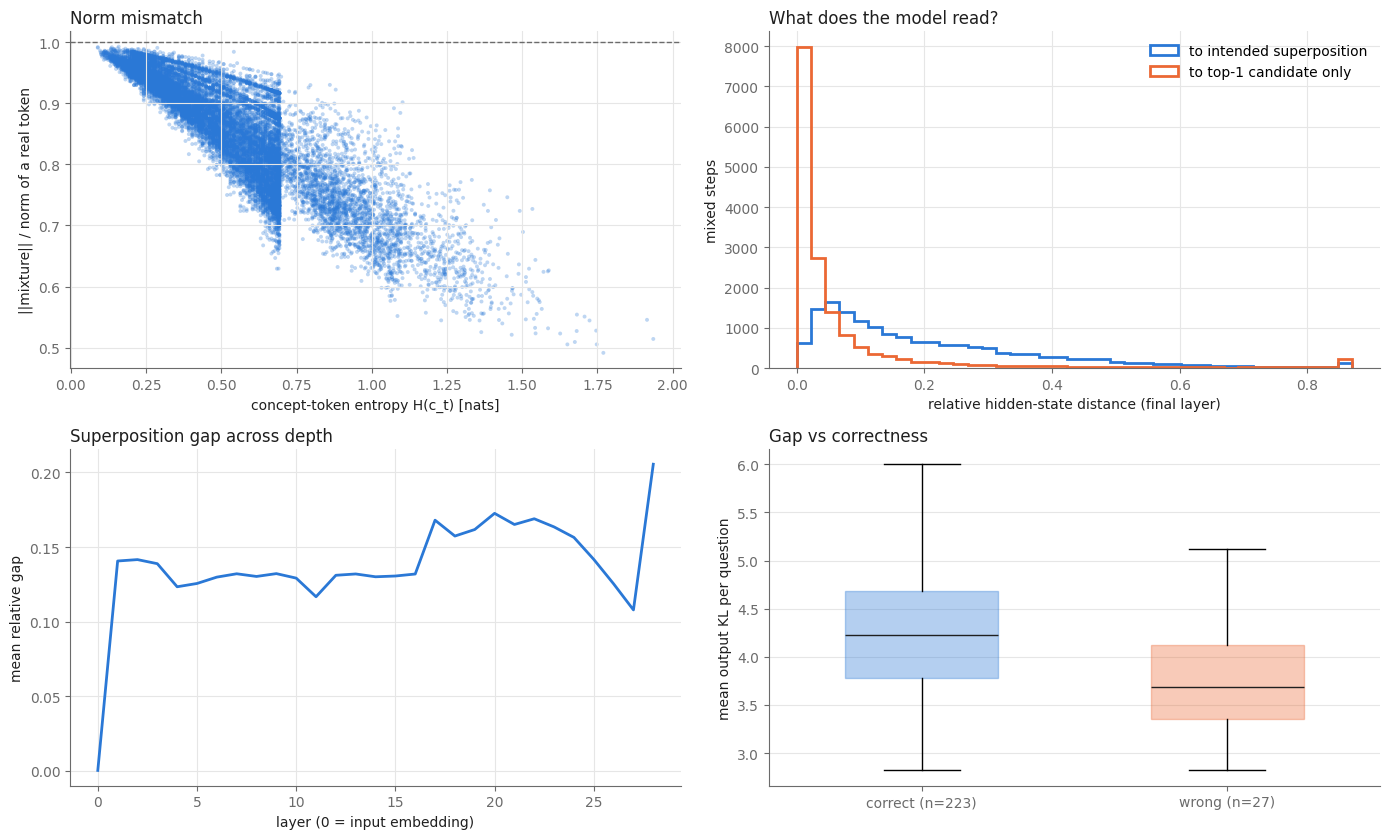

In [14]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlelocation": "left", "axes.titlecolor": INK})

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

ax = axes[0, 0]
ax.scatter(diag_paper["entropy"], diag_paper["norm_ratio"], s=8, alpha=0.3, color=BLUE, edgecolors="none")
ax.axhline(1.0, color=MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("concept-token entropy H(c_t) [nats]"); ax.set_ylabel("||mixture|| / norm of a real token")
ax.set_title("Norm mismatch")

ax = axes[0, 1]
hi = float(np.quantile(np.r_[diag_paper["gap_hidden"], diag_paper["dist_top1"]], 0.99))
bins = np.linspace(0, hi, 40)
ax.hist(diag_paper["gap_hidden"].clip(upper=hi), bins=bins, histtype="step", linewidth=2, color=BLUE, label="to intended superposition")
ax.hist(diag_paper["dist_top1"].clip(upper=hi), bins=bins, histtype="step", linewidth=2, color=ORANGE, label="to top-1 candidate only")
ax.set_xlabel("relative hidden-state distance (final layer)"); ax.set_ylabel("mixed steps")
ax.set_title("What does the model read?"); ax.legend(frameon=False)

ax = axes[1, 0]
layer_cols = [c for c in diag_paper.columns if c.startswith("gap_L")]
ax.plot(range(len(layer_cols)), diag_paper[layer_cols].mean().values, color=BLUE, linewidth=2)
ax.set_xlabel("layer (0 = input embedding)"); ax.set_ylabel("mean relative gap")
ax.set_title("Superposition gap across depth")

ax = axes[1, 1]
per_q = diag_paper.groupby("id").agg(kl=("kl_output", "mean"), correct=("correct", "first"))
groups = [per_q.loc[per_q["correct"], "kl"], per_q.loc[~per_q["correct"], "kl"]]
bp = ax.boxplot(groups, widths=0.5, patch_artist=True, showfliers=False)
for patch, c in zip(bp["boxes"], (BLUE, ORANGE)):
    patch.set_facecolor(c); patch.set_alpha(0.35); patch.set_edgecolor(c)
for med in bp["medians"]:
    med.set_color(INK)
ax.set_xticks([1, 2], [f"correct (n={len(groups[0])})", f"wrong (n={len(groups[1])})"])
ax.set_ylabel("mean output KL per question"); ax.set_title("Gap vs correctness"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [15]:
# The mixed steps with the largest output gap: which mixtures does the model misread most?
by_id = {r["id"]: r for r in soft_test}
rows = []
for _, d in diag_paper.nlargest(8, "kl_output").iterrows():
    s = by_id[d["id"]]["steps"][int(d["step"])]
    rows.append({"question": d["id"], "step": int(d["step"]), "KL": round(d["kl_output"], 3),
                 "concept token": " | ".join(f"{tok.decode([i])!r} {p:.2f}" for i, p in zip(s["ids"][:4], s["probs"][:4]))})
pd.DataFrame(rows)

,question,step,KL,concept token
0,238,142,29.908,' five' 0.56 | ' ' 0.44
1,111,118,29.169,' infl' 0.57 | ' intake' 0.37 | ' enters' 0.06
2,84,373,29.064,' which' 0.62 | ' ' 0.38
3,160,311,28.606,' Tuesday' 0.54 | ' ' 0.46
4,189,858,28.190,'1' 0.41 | 'Total' 0.31 | 'Div' 0.28
5,160,478,27.990,' that' 0.36 | ' ' 0.36 | ' I' 0.20 | ' yeah' ...
6,217,141,27.844,"' ' 0.49 | ' dah' 0.44 | ',' 0.06"
7,136,89,27.458,' there' 0.51 | ' ' 0.49


---
# Part 5: Findings

In [16]:
s, g = paper_table.iloc[0], gap_table.iloc[0]
per_q = diag_paper.groupby("id").agg(kl=("kl_output", "mean"), correct=("correct", "first"))
print(f"""METHOD
  Accuracy {s['accuracy']:.1%} on {len(soft_test)} GSM8K test questions | avg thinking tokens {s['avg think tokens']:.0f}
  thinking ended by </think> {s['stop: </think>']:.0%}, budget {s['stop: budget']:.0%}, Cold Stop {s['stop: cold stop']:.0%}
  genuinely mixed concept tokens: {s['mixed steps']:.1%} of thinking steps

LIMITATION
  norm ratio: mixtures have {g['norm ratio (mean)']:.2f}x the norm of a real token
  superposition gap: {g['gap, all layers (mean)']:.3f} (all layers), {g['gap, final layer (mean)']:.3f} (final layer)
  distance to top-1 candidate: {g['dist to top-1, final layer (mean)']:.3f} (final layer)
  model is closer to its top-1 candidate than to the superposition at {g['closer to top-1 than to superposition']:.0%} of mixed steps
  output KL to intended mixture: mean {g['output KL (mean)']:.2f}, median {g['output KL (median)']:.2f} | argmax agreement {g['argmax agrees with mixture']:.1%}
  per-question median output KL: correct {per_q.loc[per_q['correct'], 'kl'].median():.2f} vs wrong {per_q.loc[~per_q['correct'], 'kl'].median():.2f}""")

paper_table.to_csv(f"{OUT_DIR}/paper_results.csv")
gap_table.to_csv(f"{OUT_DIR}/paper_gap.csv")
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump({"run_mode": RUN_MODE, "model": MODEL_NAME, **asdict(CFG)}, f, indent=2)
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

METHOD
  Accuracy 89.2% on 250 GSM8K test questions | avg thinking tokens 1342
  thinking ended by </think> 72%, budget 28%, Cold Stop 0%
  genuinely mixed concept tokens: 21.4% of thinking steps

LIMITATION
  norm ratio: mixtures have 0.85x the norm of a real token
  superposition gap: 0.142 (all layers), 0.206 (final layer)
  distance to top-1 candidate: 0.079 (final layer)
  model is closer to its top-1 candidate than to the superposition at 90% of mixed steps
  output KL to intended mixture: mean 4.20, median 2.80 | argmax agreement 92.7%
  per-question median output KL: correct 4.22 vs wrong 3.68

saved: ['config.json', 'diag_paper.pkl', 'paper_gap.csv', 'paper_results.csv', 'soft_test.pkl', 'soft_test_time.json']


**Interpretation.**

* **The method works at small scale.** Soft Thinking solves most GSM8K questions with a 1.7B model, but only a minority of thinking steps are genuine mixtures. Most concept tokens are effectively ordinary tokens.
* **The out-of-distribution limitation is measurable.**
  * Mixtures are systematically *shorter* than real tokens, increasingly so as entropy grows.
  * The model's internal states after a mixture are far from the intended superposition.
* **The model is "single-threaded".** At most mixed steps it reads the mixture as its **top-1 candidate**, not as a superposition. This reproduces, at 1.7B scale, what follow-up work (*LLMs are Single-threaded Reasoners*, ICLR 2026) reported for large models. The largest gaps occur when incompatible continuations are mixed, e.g. a word with the bare whitespace token.
* **The gap is not a failure detector.** Compare the per-question KL of correct and wrong answers above: a larger gap does not by itself mark a wrong answer.

**Next: Notebook 2** asks whether a small trainable concept adapter, with the LLM kept frozen, can close part of this gap without hurting accuracy.